**Exercício 2**



===== INTERVALOS DE CONFIANÇA (95%) =====
Wq médio da opção 1 = 31.6825   IC95% = [29.5904, 33.7745]
Wq médio da opção 2 = 30.6573   IC95% = [27.4424, 33.8721]
W  médio da opção 1 = 38.6531   IC95% = [36.5358, 40.7705]
W  médio da opção 2 = 44.6406   IC95% = [41.3842, 47.8971]


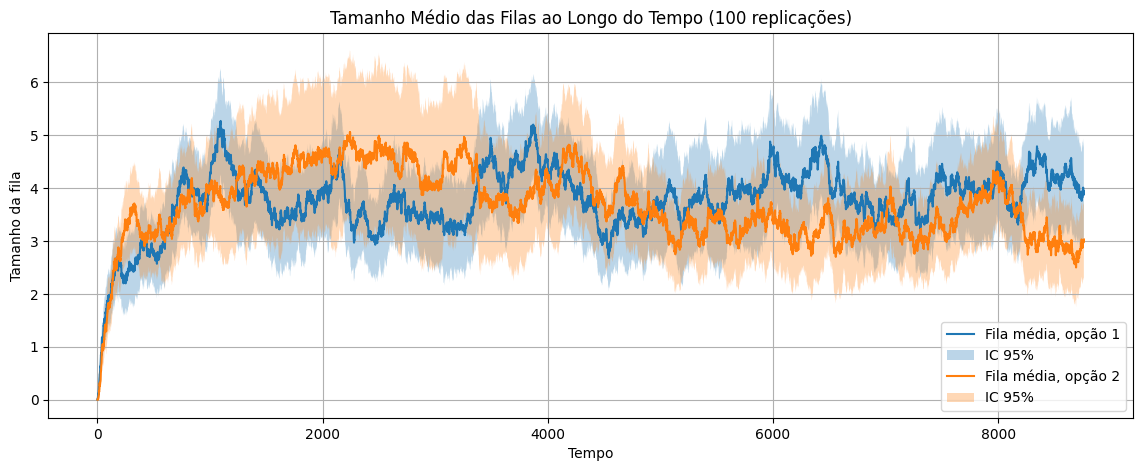

In [ ]:
from re import M
import simpy
import random
import statistics
import math
import numpy as np
import matplotlib.pyplot as plt

# ----------------------
# PARÂMETROS DO MODELO
# ----------------------
LAMBDA = 20/7/24     # taxa de chegada (λ) em navios por hora (dado taxa de chegada de 20 navios/semana)
MU1 = 1/7            # taxa de serviço (μ) em navios por hora (opção (i))
MU2 = 1/14           # taxa de serviço (μ) em navios por hora (opção (ii))
TEMPO_SIM = 24*365   # tempo de simulação (um ano, em horas)
N_REP = 100          # número de repetições

# ======================================================
# FUNÇÃO PARA RODAR UMA REPLICAÇÃO
# ======================================================
def rodar_simulacao(mu,n_bercos):

    tempos_espera = []
    tempos_sistema = []
    fila_tempo = []

    def atendimento(env, nome, servidor):
        chegada = env.now

        with servidor.request() as req:
            yield req
            tempos_espera.append(env.now - chegada)

            tempo_servico = random.expovariate(mu)
            yield env.timeout(tempo_servico)

            tempos_sistema.append(env.now - chegada)

    def chegadas(env, servidor):
        i = 0
        while True:
            yield env.timeout(random.expovariate(LAMBDA))
            i += 1
            env.process(atendimento(env, f"Cliente {i}", servidor))

    def monitor(env, servidor):
        while True:
            fila_tempo.append((env.now, len(servidor.queue)))
            yield env.timeout(1)

    env = simpy.Environment()
    servidor = simpy.Resource(env, capacity=n_bercos)
    env.process(chegadas(env, servidor))
    env.process(monitor(env, servidor))
    env.run(until=TEMPO_SIM)

    return tempos_espera, tempos_sistema, fila_tempo

def loop(mu,n_bercos):
    resultados_Wq = []
    resultados_W  = []
    resultados_fila = []
    for rep in range(N_REP):
        Wq_list, W_list, fila = rodar_simulacao(mu,n_bercos)
        resultados_Wq.append(statistics.mean(Wq_list))
        resultados_W.append(statistics.mean(W_list))
        resultados_fila.append(fila)
        #print(f"Replicação {rep+1}: Wq={statistics.mean(Wq_list):.4f}, W={statistics.mean(W_list):.4f}")
    return resultados_Wq, resultados_W, resultados_fila

def loop2(grid_tempo,filas):
    matriz_filas = []
    for fila in filas:
        tempos = [t for t, q in fila]
        valores = [q for t, q in fila]
        interp = np.interp(grid_tempo, tempos, valores)
        matriz_filas.append(interp)
    matriz_filas = np.array(matriz_filas)
    media_fila = np.mean(matriz_filas, axis=0)
    desvio_fila = np.std(matriz_filas, axis=0, ddof=1)
    return media_fila, desvio_fila

# ======================================================
# RODAR AS REPLICAÇÕES
# ======================================================
Wq1,W1,fila1 = loop(MU1,1)
Wq2,W2,fila2 = loop(MU2,2)

# ======================================================
# INTERVALO DE CONFIANÇA
# ======================================================
def intervalo_confianca(amostras):
    media = statistics.mean(amostras)
    desvio = statistics.stdev(amostras)
    n = len(amostras)
    erro = 1.96 * desvio / math.sqrt(n)
    return media - erro, media + erro, media

IC_Wq1, IC_W1 = intervalo_confianca(Wq1), intervalo_confianca(W1)
IC_Wq2, IC_W2 = intervalo_confianca(Wq2), intervalo_confianca(W2)

# ======================================================
# IMPRIMIR RELATÓRIO
# ======================================================
print("\n===== INTERVALOS DE CONFIANÇA (95%) =====")
print(f"Wq médio da opção 1 = {IC_Wq1[2]:.4f}   IC95% = [{IC_Wq1[0]:.4f}, {IC_Wq1[1]:.4f}]")
print(f"Wq médio da opção 2 = {IC_Wq2[2]:.4f}   IC95% = [{IC_Wq2[0]:.4f}, {IC_Wq2[1]:.4f}]")
print(f"W  médio da opção 1 = {IC_W1[2]:.4f}   IC95% = [{IC_W1[0]:.4f}, {IC_W1[1]:.4f}]")
print(f"W  médio da opção 2 = {IC_W2[2]:.4f}   IC95% = [{IC_W2[0]:.4f}, {IC_W2[1]:.4f}]")

# ======================================================
# PROCESSAR FILA AO LONGO DO TEMPO
# ======================================================
grid_tempo = np.arange(0, TEMPO_SIM + 1, 1)
media_fila1, desvio_fila1 = loop2(grid_tempo, fila1)
media_fila2, desvio_fila2 = loop2(grid_tempo, fila2)
IC_inf1 = media_fila1 - 1.96 * desvio_fila1 / np.sqrt(N_REP)
IC_sup1 = media_fila1 + 1.96 * desvio_fila1 / np.sqrt(N_REP)
IC_inf2 = media_fila2 - 1.96 * desvio_fila2 / np.sqrt(N_REP)
IC_sup2 = media_fila2 + 1.96 * desvio_fila2 / np.sqrt(N_REP)

# ======================================================
# GRÁFICO FINAL
# ======================================================
plt.figure(figsize=(14,5))
plt.plot(grid_tempo, media_fila1, label="Fila média, opção 1")
plt.fill_between(grid_tempo, IC_inf1, IC_sup1, alpha=0.3, label="IC 95%")
plt.plot(grid_tempo, media_fila2, label="Fila média, opção 2")
plt.fill_between(grid_tempo, IC_inf2, IC_sup2, alpha=0.3, label="IC 95%")
plt.xlabel("Tempo")
plt.ylabel("Tamanho da fila")
plt.title(f"Tamanho Médio das Filas ao Longo do Tempo ({N_REP} replicações)")
plt.grid(True)
plt.legend()
plt.show()

Conclusão: a média de tempo total no sistema é melhor na primeira opção. De fato, no tempo (diferente de Markov) o dobro de taxa não é o mesmo que o dobro de postos, com vantagem para o primeiro.


**Exercício 5**



===== INTERVALOS DE CONFIANÇA (95%) =====
Wq médio da opção 1 = 5.2513   IC95% = [5.0344, 5.4682]
Wq médio da opção 2 = 8.8681   IC95% = [8.5664, 9.1698]
W  médio da opção 1 = 11.9204   IC95% = [11.6883, 12.1525]
W  médio da opção 2 = 15.5315   IC95% = [15.2094, 15.8537]


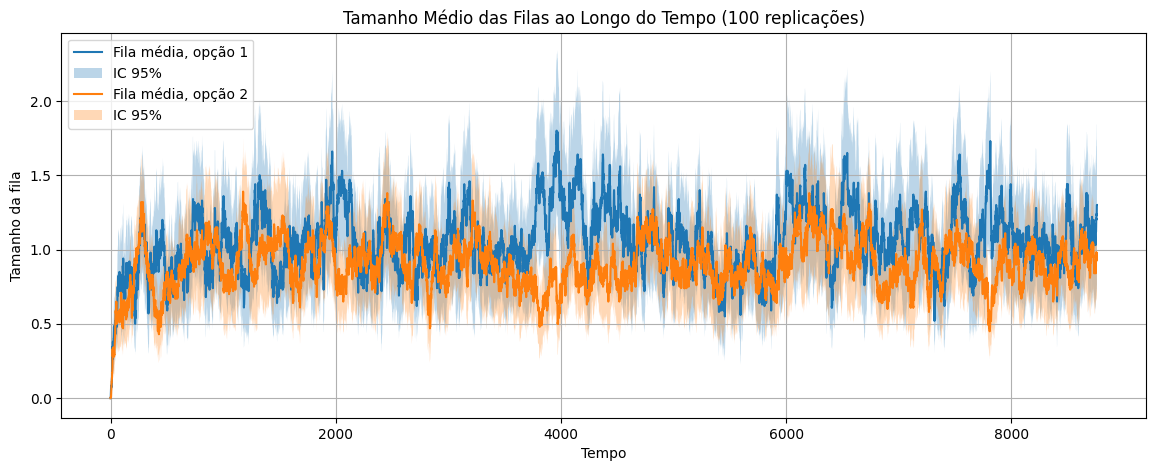

In [12]:
!pip install simpy

import simpy
import random
import statistics
import math
import numpy as np
import matplotlib.pyplot as plt

# ----------------------
# PARÂMETROS DO MODELO
# ----------------------
LAMBDA = 0.2         # taxa de chegada (λ) em navios por hora no Sudeste
MU = 0.15            # taxa de serviço (μ) em navios por hora
TEMPO_SIM = 24*365   # tempo de simulação (um ano, em horas)
N_REP = 100          # número de repetições

# ======================================================
# FUNÇÃO PARA RODAR UMA REPLICAÇÃO
# ======================================================
def Santos():
    tempos_espera = []
    tempos_sistema = []
    fila_tempo = []

    def atendimento(env, nome, servidor):
        chegada = env.now

        with servidor.request() as req:
            yield req
            tempos_espera.append(env.now - chegada)

            tempo_servico = random.expovariate(MU)
            yield env.timeout(tempo_servico)

            tempos_sistema.append(env.now - chegada)

    def chegadas(env, servidor):
        i = 0
        while True:
            yield env.timeout(random.expovariate(LAMBDA))
            i += 1
            env.process(atendimento(env, f"Cliente {i}", servidor))

    def monitor(env, servidor):
        while True:
            fila_tempo.append((env.now, len(servidor.queue)))
            yield env.timeout(1)

    env = simpy.Environment()
    servidor = simpy.Resource(env, capacity=2)
    env.process(chegadas(env, servidor))
    env.process(monitor(env, servidor))
    env.run(until=TEMPO_SIM)

    return tempos_espera, tempos_sistema, fila_tempo

def SantosSaoSebastiao():
    tempos_espera = []
    tempos_sistema = []
    fila_tempo = []

    def atendimento(env, nome, servidor):
        chegada = env.now

        with servidor.request() as req:
            yield req
            tempos_espera.append(env.now - chegada)

            tempo_servico = random.expovariate(MU)
            yield env.timeout(tempo_servico)

            tempos_sistema.append(env.now - chegada)

    def chegadas(env, servidorSantos, servidorSaoSebastiao):
        i = 0
        while True:
            yield env.timeout(random.expovariate(LAMBDA))
            i += 1
            if i % 2 == 0:
                env.process(atendimento(env, f"Cliente {i} em Santos", servidorSantos))
            else:
                env.process(atendimento(env, f"Cliente {i} em São Sebastião", servidorSaoSebastiao))

    def monitor(env, servidorSantos, servidorSaoSebastiao):
        while True:
            fila_tempo.append((env.now, len(servidorSantos.queue)))
            fila_tempo.append((env.now, len(servidorSaoSebastiao.queue)))
            yield env.timeout(1)

    env = simpy.Environment()
    servidorSantos = simpy.Resource(env, capacity=1)
    servidorSaoSebastiao = simpy.Resource(env, capacity=1)
    env.process(chegadas(env, servidorSantos, servidorSaoSebastiao))
    env.process(monitor(env, servidorSantos, servidorSaoSebastiao))
    env.run(until=TEMPO_SIM)

    return tempos_espera, tempos_sistema, fila_tempo

def loop(simulacao):
    resultados_Wq = []
    resultados_W  = []
    resultados_fila = []
    for rep in range(N_REP):
        Wq_list, W_list, fila = simulacao()
        resultados_Wq.append(statistics.mean(Wq_list))
        resultados_W.append(statistics.mean(W_list))
        resultados_fila.append(fila)
        #print(f"Replicação {rep+1}: Wq={statistics.mean(Wq_list):.4f}, W={statistics.mean(W_list):.4f}")
    return resultados_Wq, resultados_W, resultados_fila

def loop2(grid_tempo,filas):
    matriz_filas = []
    for fila in filas:
        tempos = [t for t, q in fila]
        valores = [q for t, q in fila]
        interp = np.interp(grid_tempo, tempos, valores)
        matriz_filas.append(interp)
    matriz_filas = np.array(matriz_filas)
    media_fila = np.mean(matriz_filas, axis=0)
    desvio_fila = np.std(matriz_filas, axis=0, ddof=1)
    return media_fila, desvio_fila

# ======================================================
# RODAR AS REPLICAÇÕES
# ======================================================
Wq1,W1,fila1 = loop(Santos)
Wq2,W2,fila2 = loop(SantosSaoSebastiao)

# ======================================================
# INTERVALO DE CONFIANÇA
# ======================================================
def intervalo_confianca(amostras):
    media = statistics.mean(amostras)
    desvio = statistics.stdev(amostras)
    n = len(amostras)
    erro = 1.96 * desvio / math.sqrt(n)
    return media - erro, media + erro, media

IC_Wq1, IC_W1 = intervalo_confianca(Wq1), intervalo_confianca(W1)
IC_Wq2, IC_W2 = intervalo_confianca(Wq2), intervalo_confianca(W2)

# ======================================================
# IMPRIMIR RELATÓRIO
# ======================================================
print("\n===== INTERVALOS DE CONFIANÇA (95%) =====")
print(f"Wq médio da opção 1 = {IC_Wq1[2]:.4f}   IC95% = [{IC_Wq1[0]:.4f}, {IC_Wq1[1]:.4f}]")
print(f"Wq médio da opção 2 = {IC_Wq2[2]:.4f}   IC95% = [{IC_Wq2[0]:.4f}, {IC_Wq2[1]:.4f}]")
print(f"W  médio da opção 1 = {IC_W1[2]:.4f}   IC95% = [{IC_W1[0]:.4f}, {IC_W1[1]:.4f}]")
print(f"W  médio da opção 2 = {IC_W2[2]:.4f}   IC95% = [{IC_W2[0]:.4f}, {IC_W2[1]:.4f}]")

# ======================================================
# PROCESSAR FILA AO LONGO DO TEMPO
# ======================================================
grid_tempo = np.arange(0, TEMPO_SIM + 1, 1)
media_fila1, desvio_fila1 = loop2(grid_tempo, fila1)
media_fila2, desvio_fila2 = loop2(grid_tempo, fila2)
IC_inf1 = media_fila1 - 1.96 * desvio_fila1 / np.sqrt(N_REP)
IC_sup1 = media_fila1 + 1.96 * desvio_fila1 / np.sqrt(N_REP)
IC_inf2 = media_fila2 - 1.96 * desvio_fila2 / np.sqrt(N_REP)
IC_sup2 = media_fila2 + 1.96 * desvio_fila2 / np.sqrt(N_REP)

# ======================================================
# GRÁFICO FINAL
# ======================================================
plt.figure(figsize=(14,5))
plt.plot(grid_tempo, media_fila1, label="Fila média, opção 1")
plt.fill_between(grid_tempo, IC_inf1, IC_sup1, alpha=0.3, label="IC 95%")
plt.plot(grid_tempo, media_fila2, label="Fila média, opção 2")
plt.fill_between(grid_tempo, IC_inf2, IC_sup2, alpha=0.3, label="IC 95%")
plt.xlabel("Tempo")
plt.ylabel("Tamanho da fila")
plt.title(f"Tamanho Médio das Filas ao Longo do Tempo ({N_REP} replicações)")
plt.grid(True)
plt.legend()
plt.show()

Conclusão: mais ou menos na mesma linha do último exercício, quebrar a fila em dois sistemas é menos eficiente que dobrar a quantidade de postos de atendimento no mesmo sistema (sem trabalhar com a taxa de atendimento).


**Exercício 6**



===== INTERVALOS DE CONFIANÇA (95%) =====
Wq médio no terminal principal = 0.0000   IC95% = [0.0000, 0.0000]
Wq médio no terminal secundário = 103.2544   IC95% = [89.7186, 116.7901]
W  médio no terminal principal = 15.9523   IC95% = [15.8637, 16.0408]
W  médio no terminal secundário = 119.0788   IC95% = [105.4995, 132.6582]

a) Número médio de navios no terminal principal = 1.8530182648401827
c) Taxa média de chegadas no terminal secundário = 0.05077739726027397


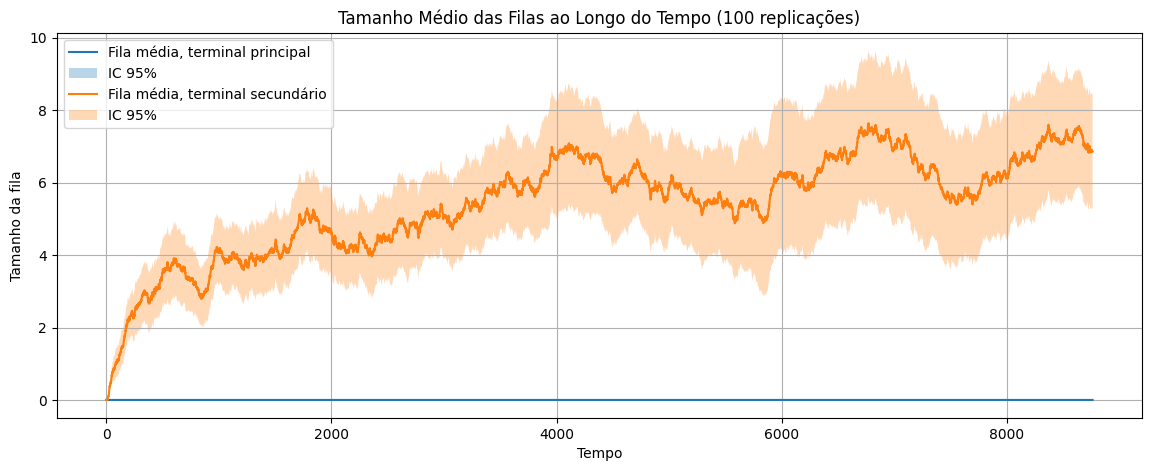

In [13]:
!pip install simpy

import simpy
import random
import statistics
import math
import numpy as np
import matplotlib.pyplot as plt

# ----------------------
# PARÂMETROS DO MODELO
# ----------------------
LAMBDA = 4/24        # taxa de chegada (λ) em navios por hora
MU = 1/16            # taxa de serviço (μ) em navios por hora
TEMPO_SIM = 24*365   # tempo de simulação (um ano, em horas)
N_REP = 100          # número de repetições
total_navios2 = 0

# ======================================================
# FUNÇÃO PARA RODAR UMA REPLICAÇÃO
# ======================================================
def Porto():
    tempos_espera1 = []
    tempos_sistema1 = []
    fila_tempo1 = []
    tempos_espera2 = []
    tempos_sistema2 = []
    fila_tempo2 = []
    num_navios1 = []

    global total_navios2
    total_navios2 = 0

    def atendimento(env, nome, servidor):
        chegada = env.now

        with servidor.request() as req:
            yield req
            if servidor == terminalPrincial:
                tempos_espera1.append(env.now - chegada)
            else:
                tempos_espera2.append(env.now - chegada)

            tempo_servico = random.expovariate(MU)
            yield env.timeout(tempo_servico)

            if servidor == terminalPrincial:
                tempos_sistema1.append(env.now - chegada)
            else:
                tempos_sistema2.append(env.now - chegada)

    def chegadas(env, terminalPrincial, terminalSecundario):
        global total_navios2
        i = 0
        while True:
            yield env.timeout(random.expovariate(LAMBDA))
            i += 1
            if terminalPrincial.count < 3:
                env.process(atendimento(env, f"Cliente {i} em 1", terminalPrincial))
            else:
                total_navios2 += 1
                env.process(atendimento(env, f"Cliente {i} em 2", terminalSecundario))

    def monitor(env, terminalPrincial, terminalSecundario):
        while True:
            fila_tempo1.append((env.now, len(terminalPrincial.queue)))
            fila_tempo2.append((env.now, len(terminalSecundario.queue)))
            num_navios1.append(terminalPrincial.count)
            yield env.timeout(1)

    env = simpy.Environment()
    terminalPrincial = simpy.Resource(env, capacity=4)
    terminalSecundario = simpy.Resource(env, capacity=1)
    env.process(chegadas(env, terminalPrincial, terminalSecundario))
    env.process(monitor(env, terminalPrincial, terminalSecundario))
    env.run(until=TEMPO_SIM)

    return tempos_espera1, tempos_sistema1, fila_tempo1, tempos_espera2, tempos_sistema2, fila_tempo2, num_navios1, total_navios2

def loop():
    resultados_Wq1 = []
    resultados_W1  = []
    resultados_fila1 = []
    resultados_Wq2 = []
    resultados_W2  = []
    resultados_fila2 = []
    resultados_num_navios1 = []
    resultados_total_navios2 = []
    for rep in range(N_REP):
        Wq_list1, W_list1, fila1, Wq_list2, W_list2, fila2, num_navios1, total_navios2 = Porto()
        resultados_Wq1.append(statistics.mean(Wq_list1))
        resultados_W1.append(statistics.mean(W_list1))
        resultados_fila1.append(fila1)
        resultados_Wq2.append(statistics.mean(Wq_list2))
        resultados_W2.append(statistics.mean(W_list2))
        resultados_fila2.append(fila2)
        resultados_num_navios1.append(statistics.mean(num_navios1))
        resultados_total_navios2.append(total_navios2)
        #print(f"Replicação {rep+1}: Wq1={statistics.mean(Wq_list1):.4f}, W2={statistics.mean(W_list1):.4f}")
        #print(f"               Wq2={statistics.mean(Wq_list2):.4f}, W2={statistics.mean(W_list2):.4f}")
    return resultados_Wq1, resultados_W1, resultados_fila1, resultados_Wq2, resultados_W2, resultados_fila2, resultados_num_navios1, resultados_total_navios2

def loop2(grid_tempo,filas):
    matriz_filas = []
    for fila in filas:
        tempos = [t for t, q in fila]
        valores = [q for t, q in fila]
        interp = np.interp(grid_tempo, tempos, valores)
        matriz_filas.append(interp)
    matriz_filas = np.array(matriz_filas)
    media_fila = np.mean(matriz_filas, axis=0)
    desvio_fila = np.std(matriz_filas, axis=0, ddof=1)
    return media_fila, desvio_fila

# ======================================================
# RODAR AS REPLICAÇÕES
# ======================================================
Wq1,W1,fila1,Wq2,W2,fila2,navios1,total2 = loop()

# ======================================================
# INTERVALO DE CONFIANÇA
# ======================================================
def intervalo_confianca(amostras):
    media = statistics.mean(amostras)
    desvio = statistics.stdev(amostras)
    n = len(amostras)
    erro = 1.96 * desvio / math.sqrt(n)
    return media - erro, media + erro, media

IC_Wq1, IC_W1 = intervalo_confianca(Wq1), intervalo_confianca(W1)
IC_Wq2, IC_W2 = intervalo_confianca(Wq2), intervalo_confianca(W2)

# ======================================================
# IMPRIMIR RELATÓRIO
# ======================================================
print("\n===== INTERVALOS DE CONFIANÇA (95%) =====")
print(f"Wq médio no terminal principal = {IC_Wq1[2]:.4f}   IC95% = [{IC_Wq1[0]:.4f}, {IC_Wq1[1]:.4f}]")
print(f"Wq médio no terminal secundário = {IC_Wq2[2]:.4f}   IC95% = [{IC_Wq2[0]:.4f}, {IC_Wq2[1]:.4f}]")
print(f"W  médio no terminal principal = {IC_W1[2]:.4f}   IC95% = [{IC_W1[0]:.4f}, {IC_W1[1]:.4f}]")
print(f"W  médio no terminal secundário = {IC_W2[2]:.4f}   IC95% = [{IC_W2[0]:.4f}, {IC_W2[1]:.4f}]")

print(f"\na) Número médio de navios no terminal principal = {statistics.mean(navios1)}")
print(f"c) Taxa média de chegadas no terminal secundário = {statistics.mean(total2)/TEMPO_SIM}")

# ======================================================
# PROCESSAR FILA AO LONGO DO TEMPO
# ======================================================
grid_tempo = np.arange(0, TEMPO_SIM + 1, 1)
media_fila1, desvio_fila1 = loop2(grid_tempo, fila1)
media_fila2, desvio_fila2 = loop2(grid_tempo, fila2)
IC_inf1 = media_fila1 - 1.96 * desvio_fila1 / np.sqrt(N_REP)
IC_sup1 = media_fila1 + 1.96 * desvio_fila1 / np.sqrt(N_REP)
IC_inf2 = media_fila2 - 1.96 * desvio_fila2 / np.sqrt(N_REP)
IC_sup2 = media_fila2 + 1.96 * desvio_fila2 / np.sqrt(N_REP)

# ======================================================
# GRÁFICO FINAL
# ======================================================
plt.figure(figsize=(14,5))
plt.plot(grid_tempo, media_fila1, label="Fila média, terminal principal")
plt.fill_between(grid_tempo, IC_inf1, IC_sup1, alpha=0.3, label="IC 95%")
plt.plot(grid_tempo, media_fila2, label="Fila média, terminal secundário")
plt.fill_between(grid_tempo, IC_inf2, IC_sup2, alpha=0.3, label="IC 95%")
plt.xlabel("Tempo")
plt.ylabel("Tamanho da fila")
plt.title(f"Tamanho Médio das Filas ao Longo do Tempo ({N_REP} replicações)")
plt.grid(True)
plt.legend()
plt.show()

Respondendo às perguntas da questão:

a) 1.85 navios em média;

b) 16 horas;

c) 0.05 navios/hora (média de 1 navio a cada 20 horas, certamente não coincidentemente cerca de 1/4 do total de chegadas no mesmo período);

d) É nula, dado que ocupação>=3 berços direciona os navios para o terminal secundário.


**Exercício 8**


Replicação 1: Wq=2.0667, W=7.0754
               Total de clientes atendidos = 43074
               Total de clientes perdidos = 535
Replicação 2: Wq=2.0994, W=7.1259
               Total de clientes atendidos = 42831
               Total de clientes perdidos = 480
Replicação 3: Wq=2.2651, W=7.2980
               Total de clientes atendidos = 43623
               Total de clientes perdidos = 539
Replicação 4: Wq=2.0063, W=6.9661
               Total de clientes atendidos = 43205
               Total de clientes perdidos = 512
Replicação 5: Wq=1.9793, W=6.9210
               Total de clientes atendidos = 43198
               Total de clientes perdidos = 465
Replicação 6: Wq=2.3891, W=7.4527
               Total de clientes atendidos = 43452
               Total de clientes perdidos = 679
Replicação 7: Wq=2.0519, W=7.0480
               Total de clientes atendidos = 43063
               Total de clientes perdidos = 477
Replicação 8: Wq=2.1895, W=7.1816
               Total de clientes at

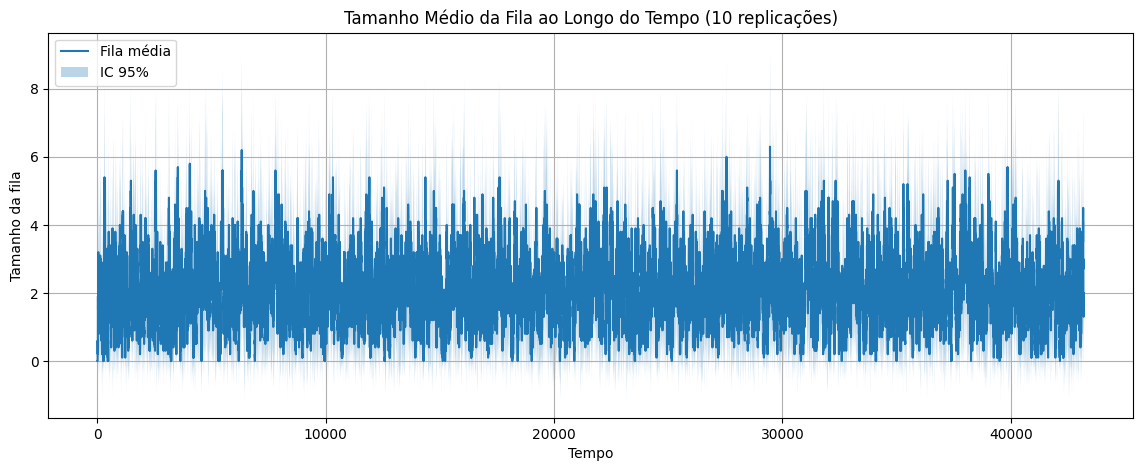

In [14]:
import simpy
import random
import statistics
import math
import numpy as np
import matplotlib.pyplot as plt

# ----------------------
# PARÂMETROS DO MODELO
# ----------------------
LAMBDA = 1            # taxa de chegadas por minuto
MU = 1/5              # taxa de atendimentos por minuto
TEMPO_SIM = 60*24*30  # um mês de operação
N_REP = 10
total_clientes = 0
clientes_perdidos = 0


# ======================================================
# FUNÇÃO PARA RODAR UMA REPLICAÇÃO
# ======================================================
def rodar_simulacao():

    tempos_espera = []
    tempos_sistema = []
    fila_tempo = []

    global total_clientes
    global clientes_perdidos
    total_clientes = 0
    clientes_perdidos = 0

    def atendimento(env, nome, servidor):
        chegada = env.now

        with servidor.request() as req:
            yield req
            tempos_espera.append(env.now - chegada)

            tempo_servico = random.expovariate(MU)
            yield env.timeout(tempo_servico)

            tempos_sistema.append(env.now - chegada)

    def chegadas(env, servidor):
        global total_clientes
        global clientes_perdidos
        i = 0
        while True:
            yield env.timeout(random.expovariate(LAMBDA))
            i += 1
            total_clientes += 1
            if len(servidor.queue) < 12:
                env.process(atendimento(env, f"Cliente {i}", servidor))
            else:
                clientes_perdidos += 1
                continue # perdemos o cliente

    def monitor(env, servidor):
        while True:
            fila_tempo.append((env.now, len(servidor.queue)))
            yield env.timeout(1)

    env = simpy.Environment()
    servidor = simpy.Resource(env, capacity=6)
    env.process(chegadas(env, servidor))
    env.process(monitor(env, servidor))
    env.run(until=TEMPO_SIM)

    return tempos_espera, tempos_sistema, fila_tempo, total_clientes, clientes_perdidos


# ======================================================
# RODAR AS REPLICAÇÕES
# ======================================================
resultados_Wq = []
resultados_W  = []
resultados_fila = []
resultados_total_clientes = []
resultados_clientes_perdidos = []
resultados_sem_fila = []

for rep in range(N_REP):
    Wq_list, W_list, fila, total_clientes, clientes_perdidos = rodar_simulacao()
    resultados_Wq.append(statistics.mean(Wq_list))
    resultados_W.append(statistics.mean(W_list))
    resultados_fila.append(fila)
    resultados_total_clientes.append(total_clientes)
    resultados_clientes_perdidos.append(clientes_perdidos)
    i = 0
    for j in range(len(fila)):
        if fila[j][1] == 0:
          i += 1
    resultados_sem_fila.append(i/TEMPO_SIM)
    print(f"Replicação {rep+1}: Wq={statistics.mean(Wq_list):.4f}, W={statistics.mean(W_list):.4f}")
    print(f"               Total de clientes atendidos = {total_clientes}")
    print(f"               Total de clientes perdidos = {clientes_perdidos}")


# ======================================================
# INTERVALO DE CONFIANÇA
# ======================================================
def intervalo_confianca(amostras):
    media = statistics.mean(amostras)
    desvio = statistics.stdev(amostras)
    n = len(amostras)
    erro = 1.96 * desvio / math.sqrt(n)
    return media - erro, media + erro, media

IC_Wq = intervalo_confianca(resultados_Wq)
IC_W  = intervalo_confianca(resultados_W)


# ======================================================
# IMPRIMIR RELATÓRIO
# ======================================================
print("\n===== INTERVALOS DE CONFIANÇA (95%) =====")
print(f"Wq médio = {IC_Wq[2]:.4f}   IC95% = [{IC_Wq[0]:.4f}, {IC_Wq[1]:.4f}]")
print(f"W  médio = {IC_W[2]:.4f}   IC95% = [{IC_W[0]:.4f}, {IC_W[1]:.4f}]")
print(f"Fração perdida sobre atendidos = {round(100*statistics.mean(resultados_clientes_perdidos)/statistics.mean(resultados_total_clientes),2)}%")
print(f"Fração do tempo sem fila = {round(100*statistics.mean(resultados_sem_fila),2)}%")

# ======================================================
# PROCESSAR FILA AO LONGO DO TEMPO
# ======================================================
grid_tempo = np.arange(0, TEMPO_SIM + 1, 1)
matriz_filas = []

for fila in resultados_fila:
    tempos = [t for t, q in fila]
    valores = [q for t, q in fila]
    interp = np.interp(grid_tempo, tempos, valores)
    matriz_filas.append(interp)

matriz_filas = np.array(matriz_filas)

media_fila = np.mean(matriz_filas, axis=0)
desvio_fila = np.std(matriz_filas, axis=0, ddof=1)

IC_inf = media_fila - 1.96 * desvio_fila / np.sqrt(N_REP)
IC_sup = media_fila + 1.96 * desvio_fila / np.sqrt(N_REP)


# ======================================================
# GRÁFICO FINAL
# ======================================================
plt.figure(figsize=(14,5))
plt.plot(grid_tempo, media_fila, label="Fila média")
plt.fill_between(grid_tempo, IC_inf, IC_sup, alpha=0.3, label="IC 95%")
plt.xlabel("Tempo")
plt.ylabel("Tamanho da fila")
plt.title(f"Tamanho Médio da Fila ao Longo do Tempo ({N_REP} replicações)")
plt.grid(True)
plt.legend()
plt.show()

Respondendo às perguntas da questão:

a) 46%;

b) 54%.

Na realidade, não são verdadeiramente complementares, pois, para (a), haveria o cenário em que os agentes estão totalmente ocupados mas a fila está vazia. Então, (a) seria (marginalmente, dado c=6) maior.
